<a href="https://colab.research.google.com/github/cristobalcresposandoval-lang/CSN/blob/main/core_proyecto_1_parte_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

El DataFrame 'df' no estaba definido. Buscando o regenerando 'ventas.csv'...
Generando dataset sintético equivalente...


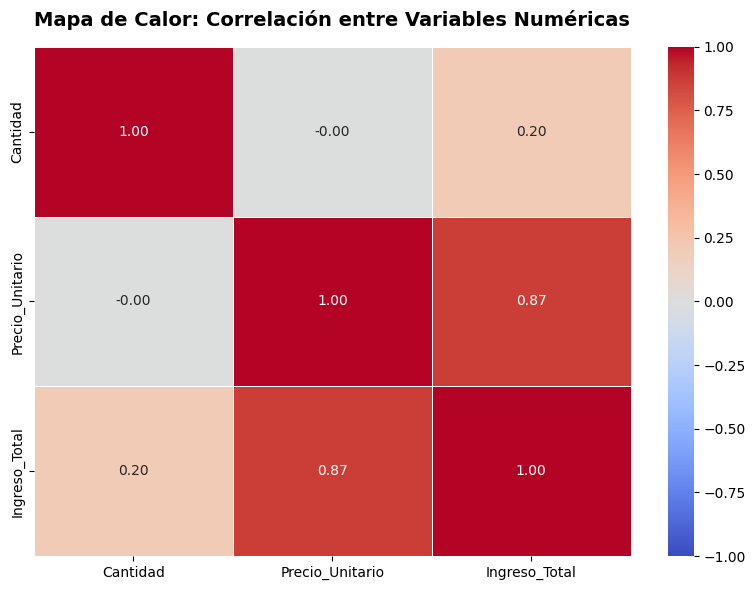

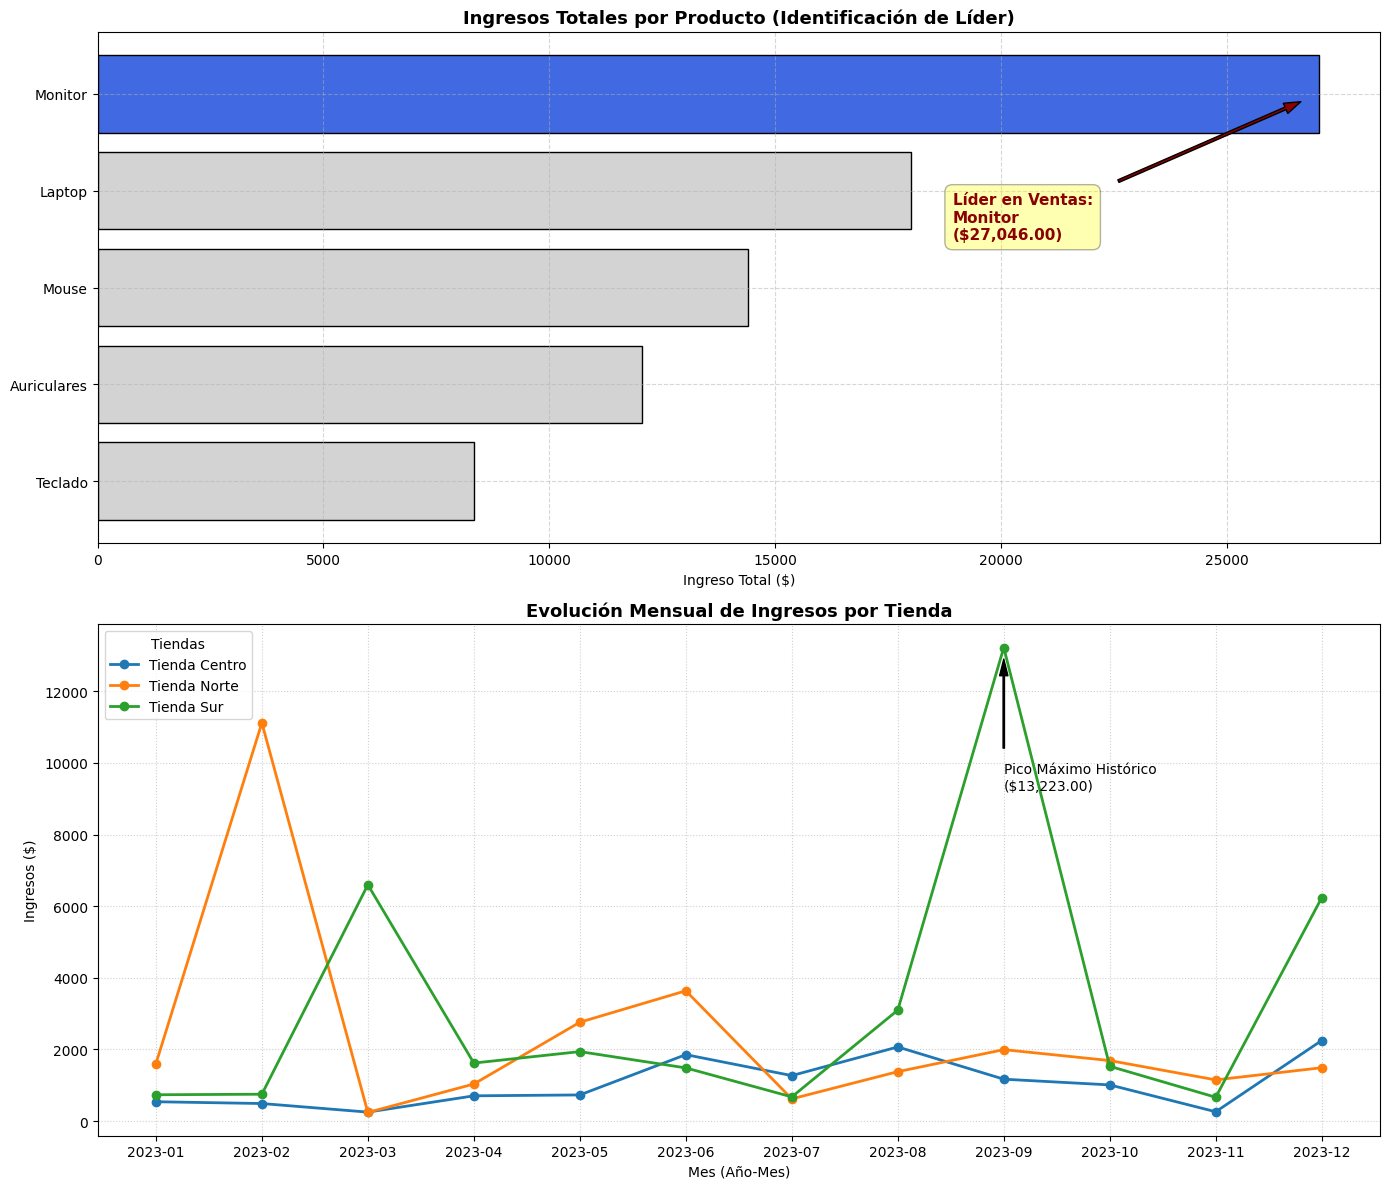

In [3]:
# =====================================================
# PARTE V: EXPLORACIÓN DE DATOS AVANZADA
# =====================================================

import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Asegurar que df esté cargado en esta sesión
try:
    _ = df.head()
except NameError:
    print("El DataFrame 'df' no estaba definido. Buscando o regenerando 'ventas.csv'...")
    file_name = "ventas.csv"
    if not os.path.exists(file_name):
        encontrado = False
        for root, dirs, files in os.walk("."):
            if file_name in files:
                file_name = os.path.join(root, file_name)
                encontrado = True
                break
        if not encontrado:
            print("Generando dataset sintético equivalente...")
            np.random.seed(42)
            fechas = pd.date_range(start="2023-01-01", end="2023-12-31", freq="D")
            productos = ["Laptop", "Teclado", "Mouse", "Monitor", "Auriculares"]
            tiendas = ["Tienda Norte", "Tienda Sur", "Tienda Centro"]
            data_demo = {
                "Fecha": np.random.choice(fechas, size=200),
                "Producto": np.random.choice(productos, size=200),
                "Tienda": np.random.choice(tiendas, size=200),
                "Cantidad": np.random.randint(1, 10, size=200),
                "Precio_Unitario": np.random.choice([15.0, 25.0, 150.0, 30.0, 999.0], size=200, p=[0.3, 0.3, 0.2, 0.15, 0.05])
            }
            df_demo = pd.DataFrame(data_demo)
            df_demo.to_csv("ventas.csv", index=False)
            file_name = "ventas.csv"

    df = pd.read_csv(file_name)
    df = df.drop_duplicates()
    df["Fecha"] = pd.to_datetime(df["Fecha"], errors="coerce")
    df["Cantidad"] = pd.to_numeric(df["Cantidad"], errors="coerce")
    df["Precio_Unitario"] = pd.to_numeric(df["Precio_Unitario"], errors="coerce")
    df = df.dropna(subset=["Fecha", "Cantidad", "Precio_Unitario", "Producto", "Tienda"])
    df["Ingreso_Total"] = df["Cantidad"] * df["Precio_Unitario"]

# 1. MATRIZ DE CORRELACIÓN Y MAPA DE CALOR
plt.figure(figsize=(8, 6))
columnas_numericas = ["Cantidad", "Precio_Unitario", "Ingreso_Total"]
corr_matrix = df[columnas_numericas].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)
plt.title("Mapa de Calor: Correlación entre Variables Numéricas", fontsize=14, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()

# 2. SUBPLOTS AVANZADOS CON ANOTACIONES, LEYENDAS Y FLECHAS
fig, axes = plt.subplots(2, 1, figsize=(14, 12))

# Subplot 1: Ingresos por Producto
ventas_producto = df.groupby("Producto")["Ingreso_Total"].sum().sort_values(ascending=True)
colors = ["lightgray" if x != ventas_producto.max() else "royalblue" for x in ventas_producto.values]

bars = axes[0].barh(ventas_producto.index, ventas_producto.values, color=colors, edgecolor="black")
axes[0].set_title("Ingresos Totales por Producto (Identificación de Líder)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Ingreso Total ($)")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Anotación y Flecha en el producto estrella
producto_estrella = ventas_producto.idxmax()
ingreso_estrella = ventas_producto.max()

axes[0].annotate(
    f"Líder en Ventas:\n{producto_estrella}\n(${ingreso_estrella:,.2f})",
    xy=(ingreso_estrella, producto_estrella),
    xytext=(ingreso_estrella * 0.7, len(ventas_producto) - 2.5),
    arrowprops=dict(facecolor='darkred', shrink=0.08, width=2, headwidth=8),
    fontsize=11,
    fontweight='bold',
    color='darkred',
    bbox=dict(boxstyle="round,pad=0.5", fc="yellow", alpha=0.3)
)

# Subplot 2: Evolución Mensual por Tienda
ventas_mensuales_tienda = df.pivot_table(
    index=df["Fecha"].dt.to_period("M").astype(str),
    columns="Tienda",
    values="Ingreso_Total",
    aggfunc="sum"
).fillna(0)

for tienda in ventas_mensuales_tienda.columns:
    axes[1].plot(
        ventas_mensuales_tienda.index,
        ventas_mensuales_tienda[tienda],
        marker="o",
        label=tienda,
        linewidth=2
    )

axes[1].set_title("Evolución Mensual de Ingresos por Tienda", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Mes (Año-Mes)")
axes[1].set_ylabel("Ingresos ($)")
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].legend(title="Tiendas", loc="upper left", fontsize=10)

# Encontrar el pico máximo histórico de ventas mensuales para destacar
max_mes = ventas_mensuales_tienda.max().max()
pos_pico = ""
for col in ventas_mensuales_tienda.columns:
    if (ventas_mensuales_tienda[col] == max_mes).any():
        pos_pico = ventas_mensuales_tienda[ventas_mensuales_tienda[col] == max_mes].index[0]

axes[1].annotate(
    f"Pico Máximo Histórico\n(${max_mes:,.2f})",
    xy=(pos_pico, max_mes),
    xytext=(pos_pico, max_mes * 0.7),
    arrowprops=dict(facecolor='black', shrink=0.1, width=1, headwidth=6),
    fontsize=10,
    color='black'
)

plt.tight_layout()
plt.show()